# Prédiction de réachat produit

## Objectif

Prédire si un produit donné sera réacheté (reordered = 1) dans la prochaine commande d'un utilisateur

Ce modèle s'appuie sur les constats de l'analyse exploratoire:
* La fidélité se traduit par la récurrence, et non par le volume panier
* Les 10 premières commandes sont la fenêtre critique de fidélisation
* L'effet client domine l'effet catégorie dans le réachat

## Approche

1. **Feature engineering**: variable à 3 niveaux: utilisateur, produit, user x produit
2. **Split temporel**: dernière commande = test (on ne fait pas de split aléatoire, donc pas de data leakage)
3. **Comparaison**: Logistic Regression (baseline) vs Random Forest vs LightGBM
4. **Evaluation**: accuracy, precision, recall, F1, ROC-AUC

## Justification des outils

| Package | Rôle | Pourquoi ce choix |
|---|---|---|
| **scikit-learn** | Logistic Regression, Random Forest, métriques | Standard de l'industrie, API cohérente, reproductible |
| **LightGBM** | Gradient boosting | Plus rapide que XGBoost sur les gros datasets tabulaires, gère les catégorielles nativement |
| **seaborn / matplotlib** | Visualisation des résultats | Cohérence avec le reste du notebook, qualité publication |

## Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys

sys.path.append("..")
from src.data_loader import get_data
from src.features import enrich_dataframe
from src.ml_features import build_all_features
from src.ml_pipeline import ReorderPipeline

# Style global
sns.set_theme(style="whitegrid", font_scale=1)
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.facecolor": "#fafafa",
    "figure.facecolor": "white",
})

COLORS = {
    "occasionnel": "#a8bfc1",
    "typique":     "#4290ba",
    "fidèle":      "#1b3a4b",
    "accent":      "#3cc494",
    "grey":        "#6b7280",
}
PAL_SEGMENTS = [COLORS["occasionnel"], COLORS["typique"], COLORS["fidèle"]]

In [3]:
# Chargement des données

data = get_data(
    raw_dir="../data/raw",
    processed_path="../data/processed/merged_orders.parquet"
)
data = enrich_dataframe(data)
print(f"Dataset: {data.shape[0]:,} lignes et {data.shape[1]} colonnes")

Chargement depuis le cache .parquet
Dataset: 32,434,489 lignes et 21 colonnes


## Etape 1. Split temporel

On sépare les données chronologiquement, et non aléatoirement:

* **Train**: toutes les commandes de chaque utilisateur sauf la dernière
* **Test**: la dernière commande de chaque utilisateur

C'est l'approche standard pour les problèmes de *next basket prediction*. Un split aléatoire causerait du **data leakage**. Le modèle verrait les commandes futures pour prédire le passé.

In [4]:
# Initialisation du pipeline
# sample_frac=0.3 pour itérer vite; passer à 1.0 pour le run final
pipeline = ReorderPipeline(data, sample_frac=0.3, random_state=42)
pipeline.split()
print()

ETAPE 1 : Split temporel
  Train : 30,294,701 lignes
  Test  : 2,139,788 lignes



## Etape 2. Feature engineering

Les features sont calculés uniquement sur le train set pour éviter le data leakage.

### Récapitulatif des features

| Niveau | Feature | Description |
|---|---|---|
| **User** | `u_total_orders` | Nombre total de commandes |
| | `u_avg_cart_size` | Taille moyenne du panier |
| | `u_avg_days_between` | Intervalle moyen entre commandes (jours) |
| | `u_reorder_rate` | Taux de réachat personnel |
| | `u_unique_products` | Produits distincts commandés |
| | `u_unique_departments` | Diversité en départements |
| | `u_unique_aisles` | Diversité en rayons |
| | `u_avg_unique_per_order` | Produits distincts par commande |
| **Produit** | `p_total_orders` | Commandes contenant ce produit |
| | `p_reorder_rate` | Taux de réachat global du produit |
| | `p_unique_users` | Acheteurs uniques |
| | `p_avg_cart_position` | Position moyenne dans le panier |
| | `p_is_organic` | Flag bio (1/0) |
| **User×Produit** | `up_nb_orders` | Fois où le user a commandé ce produit |
| | `up_reorder_rate` | Taux de réachat du user pour ce produit |
| | `up_avg_cart_position` | Position de ce produit dans le panier du user |
| | `up_order_ratio` | % des commandes du user contenant ce produit |
| | `up_orders_since_last` | Commandes depuis le dernier achat |

In [5]:
pipeline.build_features()


ETAPE 2: FEature engineering
  [1/3] Features utilisateur...
  8 features, 206,209 users
  [2/3] Features produit...
  6 features, 49,652 produits
  [3/3] Features user × produit...
  6 features, 12,422,758 paires
  Échantillonnage → 9,088,410 lignes (30%)
  Train : 9,088,410 × 20 features
  Test  : 2,139,788 × 20 features


ReorderPipeline(sample_frac=0.3, random_state=42)

In [6]:
# Vérification rapide des features
print(f"{'Feature':<30} {'Type':<8} {'NaN':>6} {'Mean':>10} {'Std':>10}")
print("-" * 70)
for col in pipeline.feature_cols_:
    s = pipeline.X_train_[col]
    print(f"{col:<30} {'num':<8} {s.isna().sum():>6} {s.mean():>10.3f} {s.std():>10.3f}")

Feature                        Type        NaN       Mean        Std
----------------------------------------------------------------------
u_total_orders                 num           0     33.251     25.225
u_avg_days_between             num           0     11.026      5.961
u_reorder_rate                 num           0      0.590      0.194
u_unique_products              num           0    127.076     82.400
u_unique_departments           num           0     13.538      3.069
u_unique_aisles                num           0     42.986     17.625
u_avg_cart_size                num           0     13.169      6.553
u_avg_unique_per_order         num           0     13.169      6.553
p_total_orders                 num           0  33679.806  74850.657
p_total_units                  num           0  33679.806  74850.657
p_reorder_rate                 num           0      0.590      0.150
p_unique_users                 num           0   8702.561  14399.009
p_avg_cart_position            n

## Etape 3. Entraînement et comparaison des modèles

Trois modèles, trois philosophies :

| Modèle | Type | Rôle |
|---|---|---|
| **Logistic Regression** | Linéaire | Baseline interprétable : si un modèle simple suffit, inutile de complexifier |
| **Random Forest** | Ensemble (bagging) | Capture les interactions non-linéaires, robuste au surapprentissage |
| **LightGBM** | Ensemble (boosting) | État de l'art sur les données tabulaires, rapide même sur plusieurs millions de lignes |

In [7]:
results = pipeline.train_and_evaluate()


ETAPE 3: Entraînement du model


/home/haja/Epitech/Projects/T-DAT-600-PAR_11/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1457: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/haja/Epitech/Projects/T-DAT-600-PAR_11/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 500 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=500).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


  [LogisticRegression] F1=0.5830  AUC=0.9002  (274.3s)
  [RandomForest] F1=0.7725  AUC=0.8701  (962.5s)
  [LightGBM] F1=0.7608  AUC=0.8686  (90.1s)


## Etape 4. Analyse des résultats

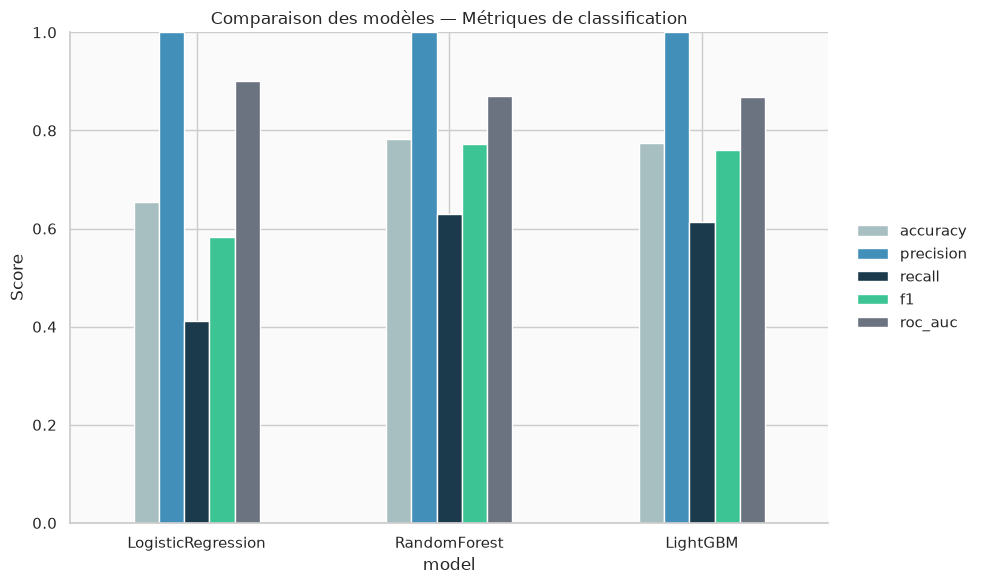

In [10]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
plot_data = results[metrics_to_plot]

fig, ax = plt.subplots(figsize=(10, 6))
plot_data.plot(kind="bar", ax=ax, color=[COLORS["occasionnel"], COLORS["typique"],
                                          COLORS["fidèle"], COLORS["accent"], COLORS["grey"]])
ax.set_ylabel("Score")
ax.set_title("Comparaison des modèles — Métriques de classification")
ax.set_ylim(0, 1)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)

# Légende placée à l'extérieur droite
ax.legend(bbox_to_anchor=(1.02, 0.5), loc="center left", frameon=False)

plt.tight_layout()
plt.show()

In [ ]:
# Classification report du meilleur modèle
best_model: int | str = results["f1"].idxmax()
print(f"Meilleur modèle (F1) : {best_model}\n")
print(pipeline.get_classification_report(best_model))

Meilleur modèle (F1) : RandomForest

              precision    recall  f1-score   support

     Nouveau       0.66      1.00      0.79    885195
    Réacheté       1.00      0.63      0.77   1254593

    accuracy                           0.78   2139788
   macro avg       0.83      0.81      0.78   2139788
weighted avg       0.86      0.78      0.78   2139788



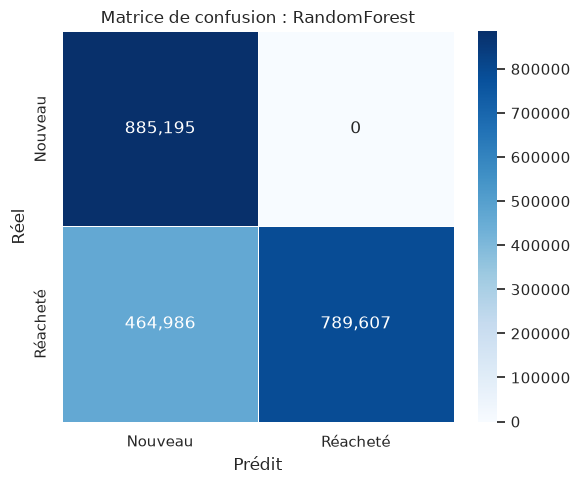

In [12]:
# Matrice de confusion du meilleur modèle
cm = pipeline.get_confusion_matrix(best_model)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt=",d", cmap="Blues",
    xticklabels=["Nouveau", "Réacheté"],
    yticklabels=["Nouveau", "Réacheté"],
    linewidths=0.5, linecolor="white",
    ax=ax
)
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
ax.set_title(f"Matrice de confusion : {best_model}")
plt.tight_layout()
plt.show()

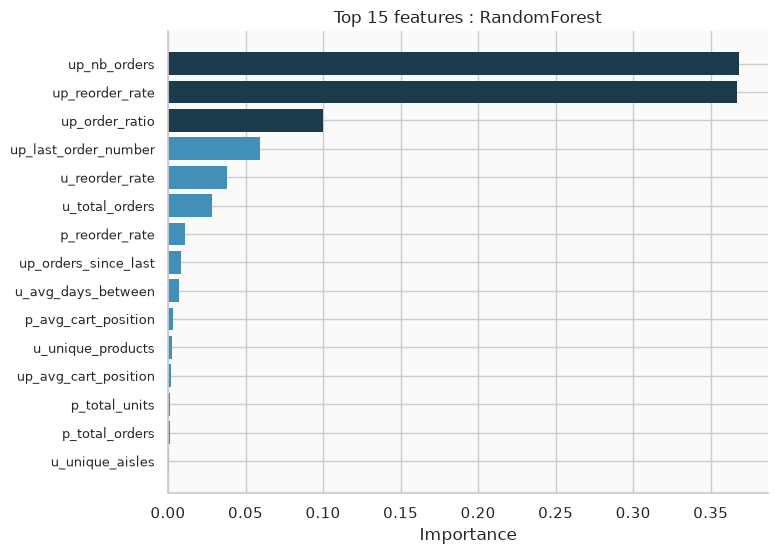

In [14]:
# Importance des features (meilleur modèle)
fi = pipeline.get_feature_importance(best_model)

fig, ax = plt.subplots(figsize=(10, 6))
top_n = 15
ax.barh(
    range(top_n),
    fi.head(top_n)["importance"],
    color=[COLORS["fidèle"] if i < 3 else COLORS["typique"] for i in range(top_n)],
    edgecolor="none"
)
ax.set_yticks(range(top_n))
ax.set_yticklabels(fi.head(top_n)["feature"], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Importance")
ax.set_title(f"Top {top_n} features : {best_model}")
plt.subplots_adjust(left=0.30)
plt.show()